In [12]:
import requests
import os
import re
import time


from numba import njit, prange
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def random_matrix(N, RANGE):
    """Genera una matriz aleatoria de tamaño NxN con valores en el rango [-RANGE, RANGE]."""
    return np.random.uniform(-RANGE, RANGE, (N, N))


@njit(parallel=True)
def matmul_numba(A, B, C, N):
    # Inicializar C a cero dentro del kernel para evitar dependencias externas
    for i in range(N):
        for j in range(N):
            C[i, j] = 0.0
            
    # Paralelismo de datos en el loop externo
    for i in prange(N):
        for k in range(N):
            for j in range(N):
                C[i, j] += A[i, k] * B[k, j]

In [3]:
A = random_matrix(2048, 10)
B = random_matrix(2048, 10)
C = np.zeros((2048, 2048), dtype=np.float64)
N = 2048

print("Ejecutando warm-up (compilación JIT)...")
matmul_numba(A, B, C, N)
    
threads_list = [1, 2, 4, 8]
results = []

filename = "resultados-py-alg-1.txt"

print("=== Numba: Paralelismo de Datos con Numba ===\n")
print(f"Tamaño de matriz: N = {N}")

# Abrir el archivo para escritura
with open(filename, 'w') as f:
    # Escribir encabezado idéntico al estilo C++
    f.write("Algoritmo: Multiplicación de Matrices con Numba\n")
    f.write(f"Tamaño de Matriz (N): {N}\n")
    f.write("Threads\tTiempo (ms)\tSpeedup (vs P=1)\tEficiencia (vs P=1)\n")
    f.write("-" * 60 + "\n")

    time_p1 = 0.0 # Variable para guardar el tiempo del caso base (1 thread)

    for p in threads_list:
        C[:] = 0.0 
        
        # Nota: En versiones recientes de Numba, set_num_threads() es preferible
        # si está disponible, pero NUMBA_NUM_THREADS sigue funcionando en muchos casos.
        os.environ['NUMBA_NUM_THREADS'] = str(p)
        
        start = time.perf_counter()
        matmul_numba(A, B, C, N)
        end = time.perf_counter()
        
        elapsed_ms = (end - start) * 1000
        
        # Guardar tiempo de referencia si es p=1
        if p == 1:
            time_p1 = elapsed_ms
            
        # Calcular Speedup y Eficiencia
        # Evitamos división por cero si time_p1 fuera 0 (improbable)
        speedup = time_p1 / elapsed_ms if elapsed_ms > 0 else 0
        efficiency = speedup / p if p > 0 else 0

        # Imprimir en consola con formato alineado
        print(f"Threads: {p:<5} Tiempo: {elapsed_ms:.2f} ms\tSpeedup: {speedup:.2f}\tEficiencia: {efficiency:.2f}")
        
        # Escribir en el archivo separado por tabuladores
        f.write(f"{p}\t{elapsed_ms:.2f}\t{speedup:.2f}\t{efficiency:.2f}\n")

print(f"\nResultados guardados en {filename}")

Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 2048
Threads: 1     Tiempo: 3168.96 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 3271.40 ms	Speedup: 0.97	Eficiencia: 0.48
Threads: 4     Tiempo: 3070.41 ms	Speedup: 1.03	Eficiencia: 0.26
Threads: 8     Tiempo: 3490.25 ms	Speedup: 0.91	Eficiencia: 0.11

Resultados guardados en resultados-py-alg-1.txt


In [4]:
def leer_resultados_tarea(ruta_archivo, nombre_alg):
    with open(ruta_archivo, 'r', encoding='utf-8') as f:
        lines = f.readlines()
    
    data = []
    header_found = False
    
    for line in lines:
        line = line.strip()
        # Ignorar líneas vacías o separadores
        if not line or line.startswith('---'):
            continue
            
        # Detectar el encabezado basado en las palabras clave
        if 'Threads' in line and 'Tiempo' in line:
            header_found = True
            continue
            
        if header_found:
            # Dividir por espacios múltiples o tabulaciones
            parts = line.split()
            if len(parts) >= 3: # Asegurar que hay datos mínimos
                try:
                    threads = int(parts[0])
                    tiempo = float(parts[1])
                    
                    # Dependiendo del archivo, las columnas de speedup/eficiencia varían
                    # Alg 1 (OpenMP Data Parallelism) tiene más columnas en tu ejemplo
                    # Alg 2 y Py-Alg-1 tienen formato: Threads Tiempo Speedup Eficiencia
                    
                    if len(parts) == 4:
                        speedup = float(parts[2])
                        eficiencia = float(parts[3])
                        speedup_vs_seq = None
                        eficiencia_vs_seq = None
                    elif len(parts) >= 6: 
                        # Caso específico de resultados-alg1.txt que tiene más métricas
                        # Threads Tiempo(ms) Speedup(vs Seq) Eficiencia(vs Seq) Speedup(vs P=1) Eficiencia(vs P=1)
                        speedup_vs_seq = float(parts[2])
                        eficiencia_vs_seq = float(parts[3])
                        speedup = float(parts[4])
                        eficiencia = float(parts[5])
                    else:
                        continue
                        
                    data.append({
                        'Algoritmo': nombre_alg,
                        'Threads': threads,
                        'Tiempo_ms': tiempo,
                        'Speedup': speedup,
                        'Eficiencia': eficiencia,
                        'Speedup_vs_Seq': speedup_vs_seq,
                        'Eficiencia_vs_Seq': eficiencia_vs_seq
                    })
                except ValueError:
                    continue
                    
    return pd.DataFrame(data)

In [8]:
## Estos valores se retornan al correr el archivo algoritmo1 y algoritmo2, sin poner números.
resultados_path = ["resultados-alg-2.txt", "resultados-alg1.txt", "resultados-py-alg-1.txt"]
resultados = {}
for path in resultados_path:
    if not os.path.exists(path):
        print(f"Archivo {path} no encontrado. Asegúrate de ejecutar los algoritmos primero.")
        exit(1)
    else:
        resultados[path] = leer_resultados_tarea(path, path.split('-')[1].split('.')[0])

df_total = pd.concat(resultados.values(), ignore_index=True)[["Algoritmo", "Threads", "Tiempo_ms", "Speedup", "Eficiencia"]]
## Reemplazamos "alg" con "alg2"
df_total["Algoritmo"] = df_total["Algoritmo"].replace({"alg1": "OpenMP", "alg": "Dividir para conquistar", "py": "Numba"})

## Ordenamos por threads
df_total = df_total.sort_values(by=["Algoritmo", "Threads"]).reset_index(drop=True)
# 3. Mostrar el resultado
print("Dataset Completo:")
df_total

Dataset Completo:


,Algoritmo,Threads,Tiempo_ms,Speedup,Eficiencia
0,Dividir para conquistar,1,6908.92,1.000000,1.000000
1,Dividir para conquistar,2,6445.58,1.071880,0.535942
2,Dividir para conquistar,4,6934.58,0.996299,0.249075
3,Dividir para conquistar,8,9806.06,0.704556,0.088069
4,Numba,1,3168.96,1.000000,1.000000
5,Numba,2,3271.40,0.970000,0.480000
6,Numba,4,3070.41,1.030000,0.260000
7,Numba,8,3490.25,0.910000,0.110000
8,OpenMP,1,5242.22,1.000000,1.000000
9,OpenMP,2,5011.46,1.046050,0.523024


In [9]:
def plot_comparacion_paralela(df, nombre_figura="nombre.jpg", titulo= "Comparación de Algoritmos Paralelos"):
    # Configuración de estilo
    
    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Paleta de colores consistente
    palette = {"OpenMP": "#1f77b4", "Dividir para conquistar": "#ff7f0e", "Numba": "#2ca02c"}
    markers = {"OpenMP": "o", "Dividir para conquistar": "s", "Numba": "^"}

    # --- Gráfico 1: Tiempo de Ejecución ---
    sns.lineplot(data=df, x="Threads", y="Tiempo_ms", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[0], linewidth=2)
    axes[0].set_title("Tiempo de Ejecución (ms)", fontsize=14)
    axes[0].set_xlabel("Número de Threads")
    axes[0].set_ylabel("Tiempo (ms)")
    axes[0].legend(title="Algoritmo")

    # --- Gráfico 2: Speedup ---
    sns.lineplot(data=df, x="Threads", y="Speedup", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[1], linewidth=2)
    
    # Línea ideal de Speedup (S = p)
    threads_unicos = sorted(df['Threads'].unique())
    axes[1].plot(threads_unicos, threads_unicos, 'k--', label='Ideal (Lineal)', alpha=0.5)
    
    axes[1].set_title("Speedup S(p)", fontsize=14)
    axes[1].set_xlabel("Número de Threads")
    axes[1].set_ylabel("Speedup")
    axes[1].legend(title="Algoritmo")

    # --- Gráfico 3: Eficiencia ---
    sns.lineplot(data=df, x="Threads", y="Eficiencia", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[2], linewidth=2)
    
    # Línea ideal de Eficiencia (E = 1)
    axes[2].axhline(y=1.0, color='k', linestyle='--', alpha=0.5, label='Ideal (100%)')
    
    axes[2].set_title("Eficiencia E(p)", fontsize=14)
    axes[2].set_xlabel("Número de Threads")
    axes[2].set_ylabel("Eficiencia")
    axes[2].legend(title="Algoritmo")

    # Ajuste final del layout
    fig.suptitle(titulo, fontsize=18, fontweight='bold')
    plt.tight_layout()
    plt.savefig(nombre_figura, dpi=300, bbox_inches='tight')
    plt.show()


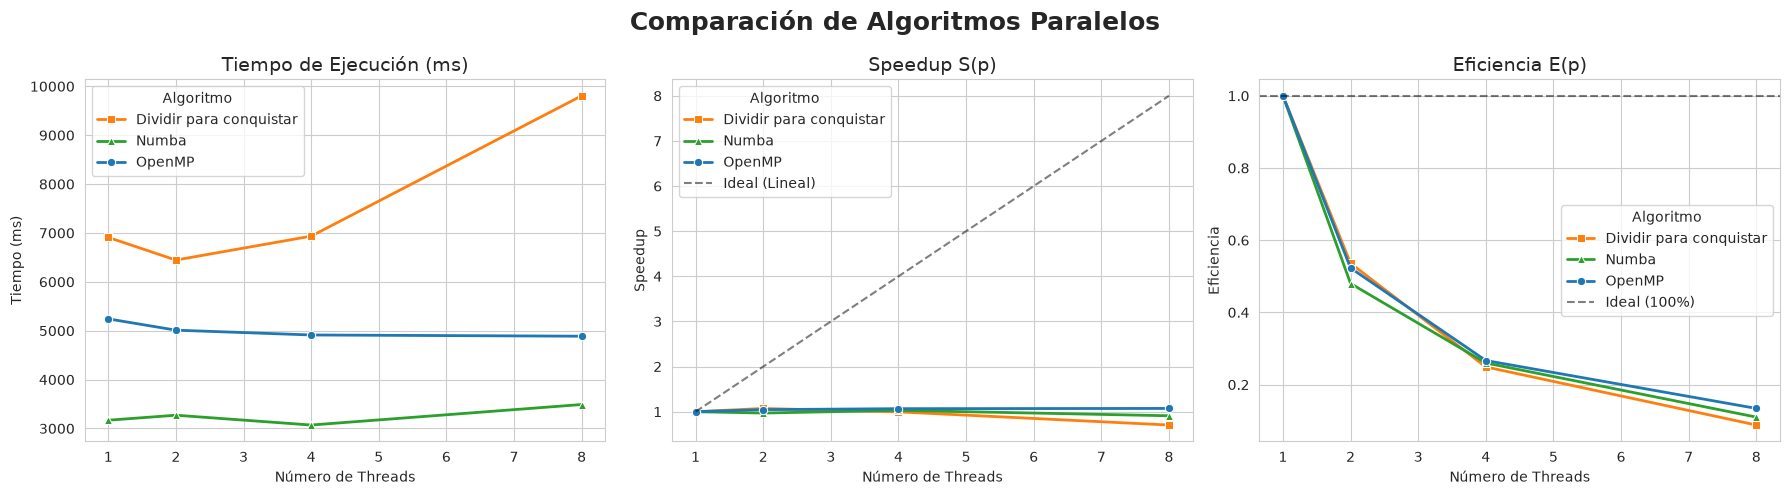

In [10]:
plot_comparacion_paralela(df_total, nombre_figura="comparacion_algoritmo.png")

In [11]:
for n in [1024, 2048, 4096]:
    print(f"\n=== Ejecutando para N = {n} ===")
    print("Ejecutando warm-up (compilación JIT)...")
    matmul_numba(A, B, C, n)
    
    threads_list = [1, 2, 4, 8]
    results = []
    print("=== Numba: Paralelismo de Datos con Numba ===\n")
    print(f"Tamaño de matriz: N = {n}")

    file_name = f"{n}-resultados-py-alg-1.txt"
    with open(file_name, 'w') as f:
        f.write("Algoritmo: Multiplicación de Matrices con Numba\n")
        f.write(f"Tamaño de Matriz (N): {N}\n")
        f.write("Threads\tTiempo (ms)\tSpeedup (vs P=1)\tEficiencia (vs P=1)\n")
        f.write("-" * 60 + "\n")
        
        time_p1 = 0.0 # Variable para guardar el tiempo del caso base (1 thread)
        for p in threads_list:
            C[:] = 0.0
            os.environ['NUMBA_NUM_THREADS'] = str(p)
            start = time.perf_counter()
            matmul_numba(A, B, C, n)
            end = time.perf_counter()
            elapsed_ms = (end - start) * 1000
            if p == 1:
                time_p1 = elapsed_ms
            speedup = time_p1 / elapsed_ms if elapsed_ms > 0 else 0
            efficiency = speedup / p if p > 0 else 0
            print(f"Threads: {p:<5} Tiempo: {elapsed_ms:.2f} ms\tSpeedup: {speedup:.2f}\tEficiencia: {efficiency:.2f}")
            f.write(f"{p}\t{elapsed_ms:.2f}\t{speedup:.2f}\t{efficiency:.2f}\n")
    print(f"\nResultados guardados en {file_name}")


=== Ejecutando para N = 1024 ===
Ejecutando warm-up (compilación JIT)...


=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 1024
Threads: 1     Tiempo: 228.25 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 246.89 ms	Speedup: 0.92	Eficiencia: 0.46
Threads: 4     Tiempo: 241.39 ms	Speedup: 0.95	Eficiencia: 0.24
Threads: 8     Tiempo: 242.38 ms	Speedup: 0.94	Eficiencia: 0.12

Resultados guardados en 1024-resultados-py-alg-1.txt

=== Ejecutando para N = 2048 ===
Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 2048
Threads: 1     Tiempo: 2372.86 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 2269.79 ms	Speedup: 1.05	Eficiencia: 0.52
Threads: 4     Tiempo: 2376.44 ms	Speedup: 1.00	Eficiencia: 0.25
Threads: 8     Tiempo: 2270.55 ms	Speedup: 1.05	Eficiencia: 0.13

Resultados guardados en 2048-resultados-py-alg-1.txt

=== Ejecutando para N = 4096 ===
Ejecutando warm-up (compilación JIT)...
=== Numba: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 4096
Thread

In [28]:
def cargar_dataset_resultados(ruta_archivos):
    """
    Carga los resultados de los archivos .txt generados por los algoritmos
    y crea un DataFrame consolidado.
    """
    data_list = []
    
    for nombre_key, ruta in ruta_archivos.items():
        if not os.path.exists(ruta):
            print(f"Advertencia: El archivo {ruta} no existe.")
            continue
            
        # 1. Determinar Algoritmo y N desde el nombre del archivo/clave
        alg = "Desconocido"
        n_val = 2048 # Default
        
        if 'alg1' in nombre_key or 'alg-1' in nombre_key:
            alg = "OpenMP"
        elif 'alg2' in nombre_key or 'alg-2' in nombre_key:
            alg = "Dividir para conquistar"
        elif 'py' in nombre_key or 'numba' in nombre_key:
            alg = "Numba"
            
        # Extraer N usando regex o búsqueda simple en el nombre
        match_n = re.search(r'(\d{3,4})', nombre_key)
        if match_n:
            n_val = int(match_n.group(1))

        try:
            # 2. Leer el archivo detectando dónde empiezan los datos tabulares
            # Leemos todo el contenido primero para encontrar la línea de encabezados
            with open(ruta, 'r') as f:
                lines = f.readlines()
            
            # Buscamos la línea que contiene "Threads" (el encabezado de la tabla)
            header_line_idx = None
            for i, line in enumerate(lines):
                if "Threads" in line and "\t" in line:
                    header_line_idx = i
                    break
            
            if header_line_idx is None:
                print(f"No se encontró encabezado de tabla en {ruta}")
                continue
                
            # Leemos el CSV saltando las líneas anteriores al encabezado
            df_temp = pd.read_csv(
                ruta, 
                sep='\t', 
                skiprows=header_line_idx, # Saltamos hasta la línea del encabezado
                engine='python',
                on_bad_lines='skip' # Ignora líneas mal formadas si quedan residuos
            )
            
            # 3. Limpieza y Estandarización de Columnas
            # Eliminamos espacios en blanco en los nombres de las columnas
            df_temp.columns = df_temp.columns.str.strip()
            
            # Mapeo de nombres posibles a nombres estándar
            col_map = {}
            for col in df_temp.columns:
                if 'Thread' in col: col_map[col] = 'Threads'
                elif 'Tiempo' in col or 'Time' in col: col_map[col] = 'Tiempo_ms'
                elif 'Speedup' in col: col_map[col] = 'Speedup'
                elif 'Eficiencia' in col or 'Efficiency' in col: col_map[col] = 'Eficiencia'
            
            df_temp = df_temp.rename(columns=col_map)
            
            # Añadir metadatos
            df_temp['Algoritmo'] = alg
            df_temp['N'] = n_val
            
            # Asegurar tipos numéricos
            for c in ['Threads', 'Tiempo_ms', 'Speedup', 'Eficiencia']:
                if c in df_temp.columns:
                    df_temp[c] = pd.to_numeric(df_temp[c], errors='coerce')
            
            # Seleccionar columnas finales
            cols_finales = ['Algoritmo', 'N', 'Threads', 'Tiempo_ms']
            if 'Speedup' in df_temp.columns: cols_finales.append('Speedup')
            if 'Eficiencia' in df_temp.columns: cols_finales.append('Eficiencia')
            
            # Eliminar filas donde el tiempo sea NaN (por errores de lectura)
            df_temp = df_temp.dropna(subset=['Tiempo_ms'])
            
            data_list.append(df_temp[cols_finales])
            
        except Exception as e:
            print(f"Error procesando {ruta}: {e}")

    if data_list:
        final_df = pd.concat(data_list, ignore_index=True)
        return final_df
    else:
        return pd.DataFrame()

In [49]:
## Los resultados disponibles se hacen al correr los valores con algoritmox N 
## Siendo N el tamaño de la matriz, los archivos les cambie el nombre a mano
## Dejé disponible los resultados del computador en las carpetas "resultados-computador-x" para cada computador
computador_deseado = 1
archivos_a_procesar = {
    "alg1_1024": f"./resultados-computador-{computador_deseado}/1024-resultados-alg1.txt",
    "alg2_1024": f"./resultados-computador-{computador_deseado}/1024-resultados-alg-2.txt",
    "py_1024":   f"./resultados-computador-{computador_deseado}/1024-resultados-py-alg-1.txt",
    
    "alg1_2048": f"./resultados-computador-{computador_deseado}/2048-resultados-alg1.txt",
    "alg2_2048": f"./resultados-computador-{computador_deseado}/2048-resultados-alg-2.txt",
    "py_2048":   f"./resultados-computador-{computador_deseado}/2048-resultados-py-alg-1.txt",
    
    "alg1_4096": f"./resultados-computador-{computador_deseado}/4096-resultados-alg1.txt",
    "alg2_4096": f"./resultados-computador-{computador_deseado}/4096-resultados-alg-2.txt",
    "py_4096":   f"./resultados-computador-{computador_deseado}/4096-resultados-py-alg-1.txt",
}

dataset_N = cargar_dataset_resultados(archivos_a_procesar)

In [50]:
## Ordenar por threads y algoritmo 

dataset_N = dataset_N.sort_values(by=['N', 'Threads'])
dataset_N.head(10)

,Algoritmo,N,Threads,Tiempo_ms,Speedup,Eficiencia
0,OpenMP,1024,1.0,906.866,1.000000,1.000000
4,Dividir para conquistar,1024,1.0,951.695,1.000000,1.000000
8,Numba,1024,1.0,228.250,1.000000,1.000000
1,OpenMP,1024,2.0,1266.490,0.716049,0.358024
5,Dividir para conquistar,1024,2.0,734.580,1.295560,0.647781
9,Numba,1024,2.0,246.890,0.920000,0.460000
2,OpenMP,1024,4.0,915.726,0.990325,0.247581
6,Dividir para conquistar,1024,4.0,698.150,1.363170,0.340792
10,Numba,1024,4.0,241.390,0.950000,0.240000
3,OpenMP,1024,8.0,838.213,1.081900,0.135238


In [51]:
dataset_1024 = dataset_N[dataset_N["N"] == 1024]
dataset_2048 = dataset_N[dataset_N["N"] == 2048]
dataset_4096 = dataset_N[dataset_N["N"] == 4096]

In [52]:
dataset_4096

,Algoritmo,N,Threads,Tiempo_ms,Speedup,Eficiencia
24,OpenMP,4096,1.0,63516.60,1.000000,1.000000
28,Dividir para conquistar,4096,1.0,60330.50,1.000000,1.000000
32,Numba,4096,1.0,19135.41,1.000000,1.000000
25,OpenMP,4096,2.0,55599.20,1.142400,0.571200
29,Dividir para conquistar,4096,2.0,64873.10,0.929977,0.464988
33,Numba,4096,2.0,20281.41,0.940000,0.470000
26,OpenMP,4096,4.0,54218.60,1.171490,0.292873
30,Dividir para conquistar,4096,4.0,50901.60,1.185240,0.296309
34,Numba,4096,4.0,23278.44,0.820000,0.210000
27,OpenMP,4096,8.0,53766.20,1.181350,0.147668


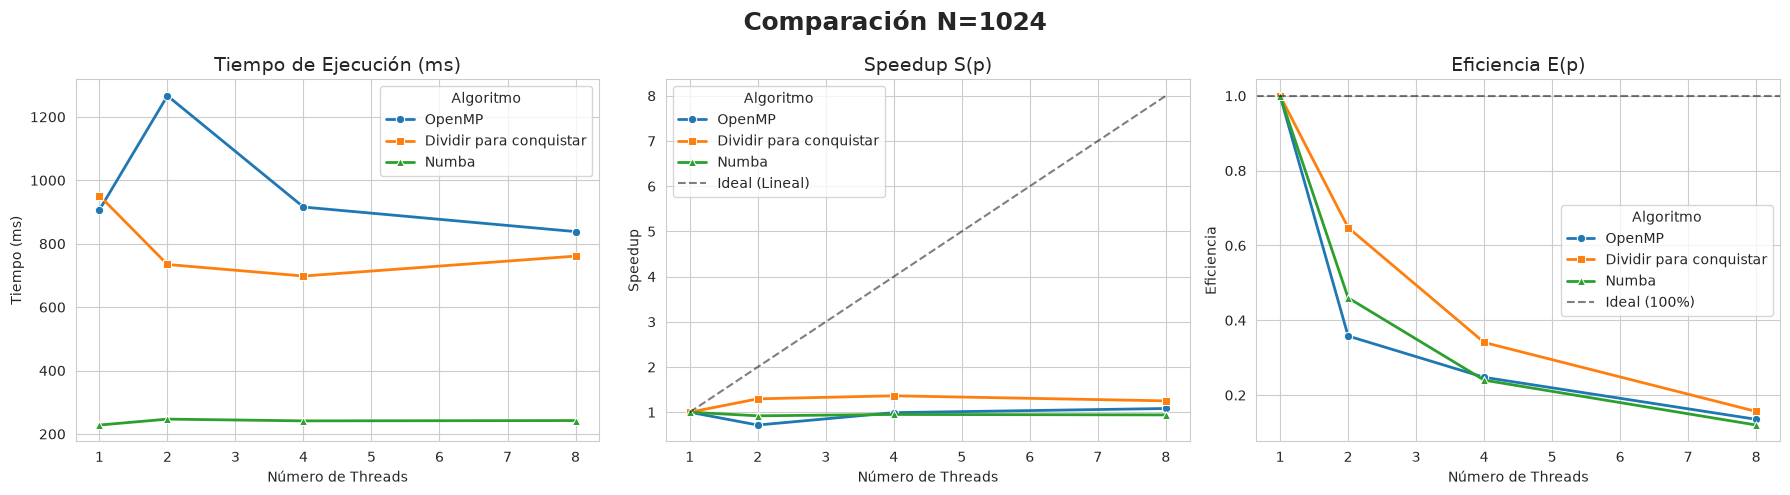

In [42]:
plot_comparacion_paralela(dataset_1024, nombre_figura="comparacion_algoritmo_1024.png", titulo="Comparación N=1024")

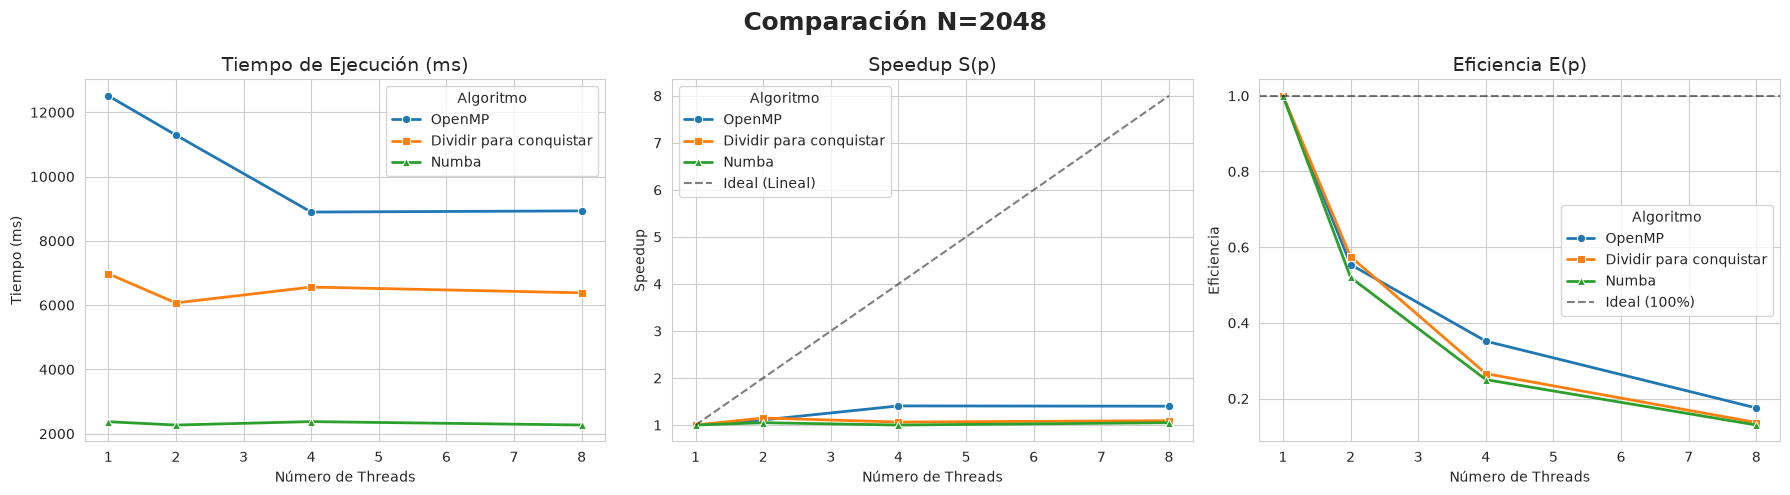

In [43]:
plot_comparacion_paralela(dataset_2048, nombre_figura="comparacion_algoritmo_2048.png", titulo="Comparación N=2048")

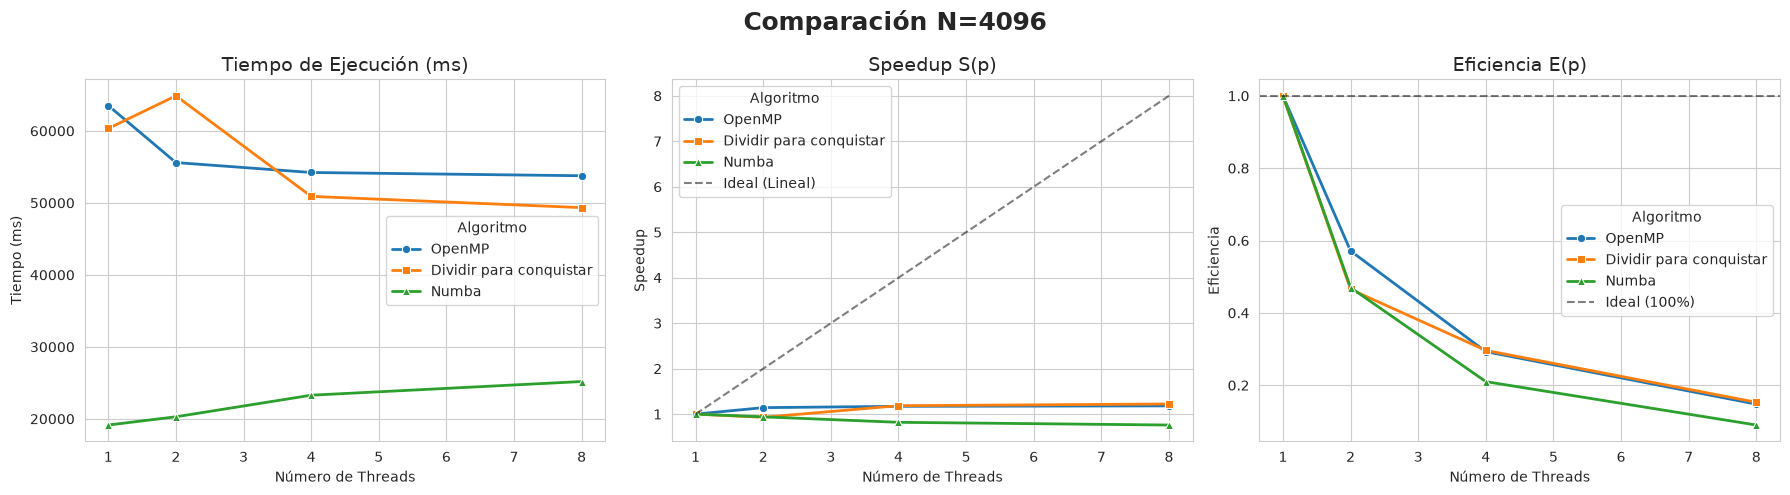

In [53]:
plot_comparacion_paralela(dataset_4096, nombre_figura="comparacion_algoritmo_4096.png", titulo="Comparación N=4096")